# Fix 3 on real data: z-score vs conformal surprise

Notebook nạp hai bộ dữ liệu đã tiền xử lý của Impala và vẽ lại các hình minh họa Fix 3 bằng dữ liệu thật:

| Bộ dữ liệu | Thư mục | Đặc trưng hành vi |
|---|---|---|
| **Old (z-score)** | `data/2011-chevrolet-impala/preprocessed_window` | 12 đặc trưng node, z-score theo normal của từng ID |
| **New (surprise + payload)** | `data/2011-chevrolet-impala/preprocessed_v3_variant` | 15 đặc trưng node (thêm 3 đặc trưng payload), mức bất ngờ conformal |

Các hình:
1. **Cùng một thang đo?** Với lưu lượng bình thường, phân vị 99 của từng (CAN ID, đặc trưng): dao động lớn với z-score, gần như không đổi với mức bất ngờ.
2. **Attack nhìn thế nào?** Giá trị của node bị tấn công trên đặc trưng phân biệt tốt nhất của từng attack: z-score có độ lớn và dấu khác nhau giữa các attack; mức bất ngờ dồn về cùng một vùng.
3. **Payload continuity:** một chuỗi frame thật quanh frame bị chèn, và phân bố đặc trưng `spike` của node bị tấn công so với node bình thường.

Chỉ cần CPU. Chạy từ thư mục gốc dự án; hình lưu ở `figures/fix3_real/` (PDF và PNG), nhãn trên hình bằng tiếng Anh.

In [1]:
import json, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(".")
OLD_DIR = ROOT / "../data/2011-chevrolet-impala/preprocessed_window"
NEW_DIR = ROOT / "../data/2011-chevrolet-impala/preprocessed_v3_variant"
RAW_DIR = ROOT / "../data/2011-chevrolet-impala"
SPLIT = "test"                      # "test" or "val"
FIG = ROOT / "figures/fix3_real"
FIG.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["normal", "dos", "fuzzing", "gear", "interval", "rpm", "speed",
               "standstill", "systematic", "combined"]
ATTACKS_SLIDE = ["dos", "rpm", "standstill"]                               # strong deviations: slide figure
ATTACKS_ALL = ["dos", "interval", "gear", "rpm", "speed", "standstill"]     # attacks on known CAN IDs: backup figure
BASE_NAMES = (["frequency", "inter-arrival mean", "inter-arrival std"]
              + [f"byte {i} mean" for i in range(8)] + ["byte change rate"])
PAYLOAD_NAMES = ["payload jump", "payload spike", "bytes changed"]

INK, SLATE, LINE = "#1E2B3C", "#5E6B78", "#9AA5B1"
TEAL, TEAL_L, OCHRE, OCHRE_L, BLUE = "#2F7F7A", "#E2F1EF", "#C9781E", "#FCEFDD", "#4C72B0"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": LINE, "axes.labelcolor": SLATE,
                     "xtick.color": SLATE, "ytick.color": SLATE, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(FIG / f"{name}.pdf"); plt.savefig(FIG / f"{name}.png", dpi=220)

## 1. Nạp dữ liệu thành bảng node

In [2]:
def load_windows(path):
    try:
        import torch
        return torch.load(path, weights_only=False)
    except ImportError:
        with open(path, "rb") as f:
            return pickle.load(f)

def node_table(data_dir, split=SPLIT):
    meta = json.load(open(Path(data_dir) / "metadata.json"))
    ws = load_windows(Path(data_dir) / f"windows_{split}.pt")
    xb, atk, cid, cls = [], [], [], []
    for w in ws:
        x = np.asarray(w["xb"], dtype=np.float32)
        xb.append(x)
        atk.append(np.asarray(w["node_atk"], dtype=np.float32) > 0)
        cid.append(np.asarray(w["can_id_indices"], dtype=np.int64))
        cls.append(np.full(len(x), int(w["label"]), dtype=np.int16))
    inv = {int(v): int(k) for k, v in meta.get("vocab", {}).items()}
    T = {"xb": np.concatenate(xb), "atk": np.concatenate(atk), "cid": np.concatenate(cid),
         "cls": np.concatenate(cls), "meta": meta, "id_hex": lambda i: f"0x{inv[i]:03X}" if i in inv else f"#{i}"}
    T["n_feat"] = T["xb"].shape[1] - 1                # last column = unknown-ID flag
    return T

OLD = node_table(OLD_DIR)
NEW = node_table(NEW_DIR)
for name, T in (("old (z-score)", OLD), ("new (surprise)", NEW)):
    print(f"{name:<16} nodes {len(T['xb']):>8,}  node features {T['n_feat']:>2}  "
          f"behavior_norm = {T['meta'].get('behavior_norm', 'zscore')}  "
          f"profile_files = {T['meta'].get('profile_files', 'all')}")

old (z-score)    nodes  754,763  node features 12  behavior_norm = zscore  profile_files = all
new (surprise)   nodes  754,763  node features 15  behavior_norm = surprise  profile_files = ['dos', 'fuzzing', 'gear', 'interval', 'rpm']


## 2. Lưu lượng bình thường có cùng một thang đo không?

Với mỗi cặp (CAN ID, đặc trưng) có đủ node bình thường, tính phân vị 99 của độ lệch (|z| ở dữ liệu cũ, s ở dữ liệu mới). Nếu thước đo thống nhất, con số này phải gần như giống nhau ở mọi ID và mọi đặc trưng.

99th percentile on normal traffic, across CAN IDs (min / median / max):


,old: |z| p99,new: s p99
feature,,
frequency,0.06 / 3.24 / 6.74,0.0 / 1.43 / 2.38
inter-arrival mean,0.04 / 3.33 / 6.82,0.0 / 1.68 / 2.44
inter-arrival std,0.0 / 0.7 / 6.01,-0.0 / 0.72 / 2.21
byte 0 mean,0.0 / 0.0 / 7.12,-0.0 / -0.0 / 2.52
byte 1 mean,0.0 / 0.0 / 4.96,-0.0 / -0.0 / 3.0
byte 2 mean,0.0 / 0.0 / 4.2,-0.0 / 0.0 / 3.0
byte 3 mean,0.0 / 0.0 / 4.2,-0.0 / 0.0 / 2.28
byte 4 mean,0.0 / 0.0 / 5.89,-0.0 / -0.0 / 2.56
byte 5 mean,0.0 / 0.0 / 5.76,-0.0 / -0.0 / 2.79


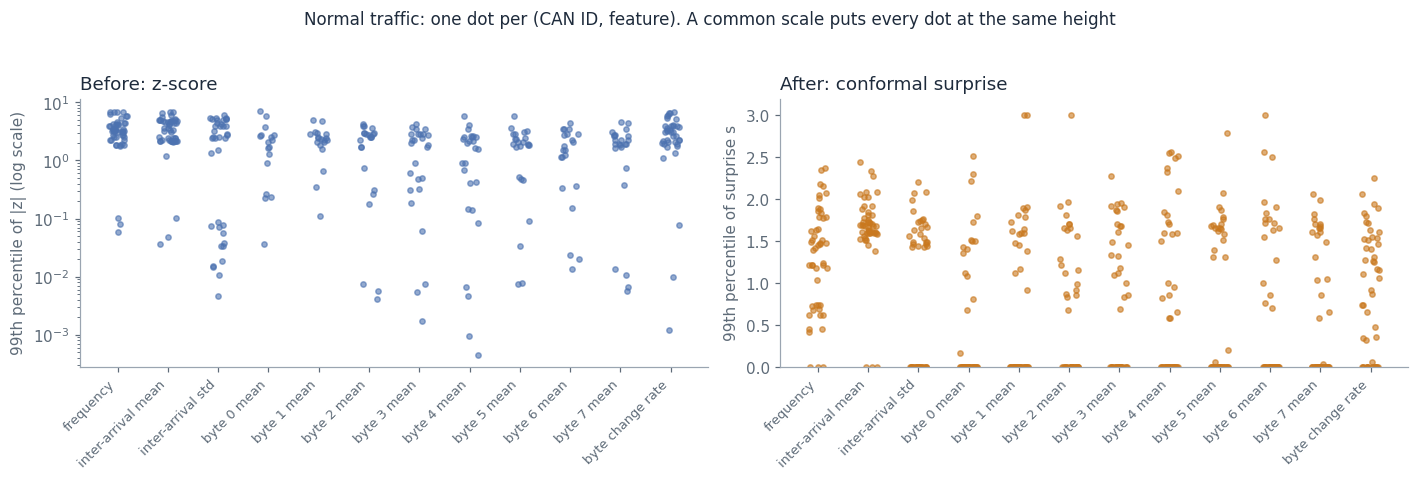

In [3]:
def p99_per_id_feature(T, absolute, min_nodes=200):
    normal = (T["cls"] == 0) & (T["xb"][:, -1] < 0.5)          # normal windows, known IDs
    rows = []
    for k in range(min(12, T["n_feat"])):                      # the 12 base features, same in both
        v = T["xb"][normal, k]; c = T["cid"][normal]
        if absolute:
            v = np.abs(v)
        df = pd.DataFrame({"cid": c, "v": v})
        q = df.groupby("cid")["v"].agg(["count", lambda s: np.quantile(s, 0.99)])
        q.columns = ["count", "p99"]
        q = q[q["count"] >= min_nodes]
        rows += [{"feature": BASE_NAMES[k], "cid": i, "p99": p} for i, p in q["p99"].items()]
    return pd.DataFrame(rows)

p_old = p99_per_id_feature(OLD, absolute=True)
p_new = p99_per_id_feature(NEW, absolute=False)
summary = pd.DataFrame({
    "old: |z| p99": p_old.groupby("feature")["p99"].describe()[["min", "50%", "max"]].round(2).astype(str).agg(" / ".join, axis=1),
    "new: s p99": p_new.groupby("feature")["p99"].describe()[["min", "50%", "max"]].round(2).astype(str).agg(" / ".join, axis=1),
}).reindex(BASE_NAMES)
print("99th percentile on normal traffic, across CAN IDs (min / median / max):")
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (df, title, col, ylab) in zip(axes, [
        (p_old, "Before: z-score", BLUE, "99th percentile of |z| (log scale)"),
        (p_new, "After: conformal surprise", OCHRE, "99th percentile of surprise s")]):
    feats = [f for f in BASE_NAMES if f in set(df["feature"])]
    for i, f in enumerate(feats):
        v = df[df.feature == f]["p99"].values
        ax.scatter(np.full(len(v), i) + np.random.uniform(-0.18, 0.18, len(v)), v, s=12, alpha=0.6, color=col)
    ax.set_xticks(range(len(feats))); ax.set_xticklabels(feats, rotation=45, ha="right", fontsize=8.5)
    ax.set_ylabel(ylab); ax.set_title(title, loc="left", fontsize=12, color=INK)
axes[0].set_yscale("log")
axes[1].set_ylim(0, 3.2)
fig.suptitle("Normal traffic: one dot per (CAN ID, feature). A common scale puts every dot at the same height",
             y=1.03, fontsize=11, color=INK)
fig.tight_layout(); savefig("fig1_normal_scale"); plt.show()

## 3. Attack trông thế nào trên hai thang đo?

Với mỗi attack, chọn đặc trưng phân biệt tốt nhất (AUROC trên dữ liệu cũ, node bị tấn công so với node bình thường **cùng CAN ID**), rồi so giá trị của node bị tấn công trên hai thang đo. Cùng đặc trưng được dùng cho cả hai bộ dữ liệu.

- **Hình cho slide** (`fig2_attacks_two_scales`): chỉ các attack có độ lệch mạnh (`ATTACKS_SLIDE`). Thông điệp: cùng một độ lệch mạnh, z-score khác nhau về độ lớn và dấu, surprise cho cùng một giá trị.
- **Hình dự phòng** (`fig2b_attacks_two_scales_all`): mọi attack trên CAN ID đã biết (`ATTACKS_ALL`). Với đặc trưng yếu, cả hai thang đo đều không tách được: surprise đổi thang đo, không tạo ra khả năng phân biệt mới.

,target IDs,feature,attacked nodes,old: median z,old: outside normal 5-95%,old: AUROC,new: median s,new: AUROC
attack,,,,,,,,
dos,"0x000, 0x0C1",frequency,1112,16.125,True,1.000,3.000,0.999
interval,0x3E9,frequency,1089,2.494,False,0.933,0.625,0.933
gear,0x1F5,byte 6 mean,657,0.235,False,0.947,0.895,0.935
rpm,0x0C9,byte 6 mean,947,-4.052,True,0.977,3.000,0.939
speed,0x3E9,frequency,1414,2.494,False,0.906,0.625,0.902
standstill,0x0C9,byte 6 mean,505,-3.201,True,1.000,3.000,1.000


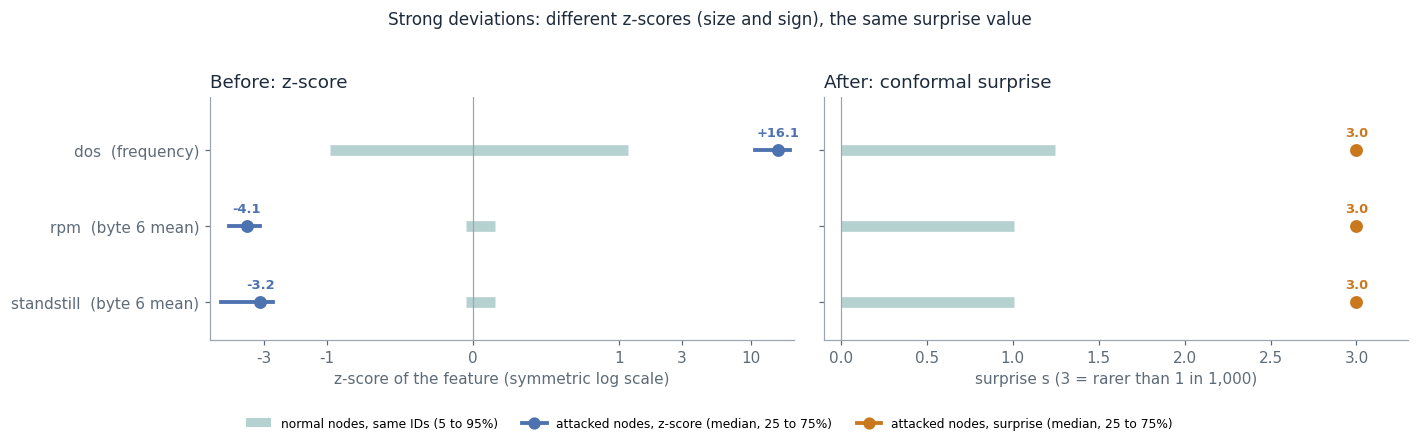

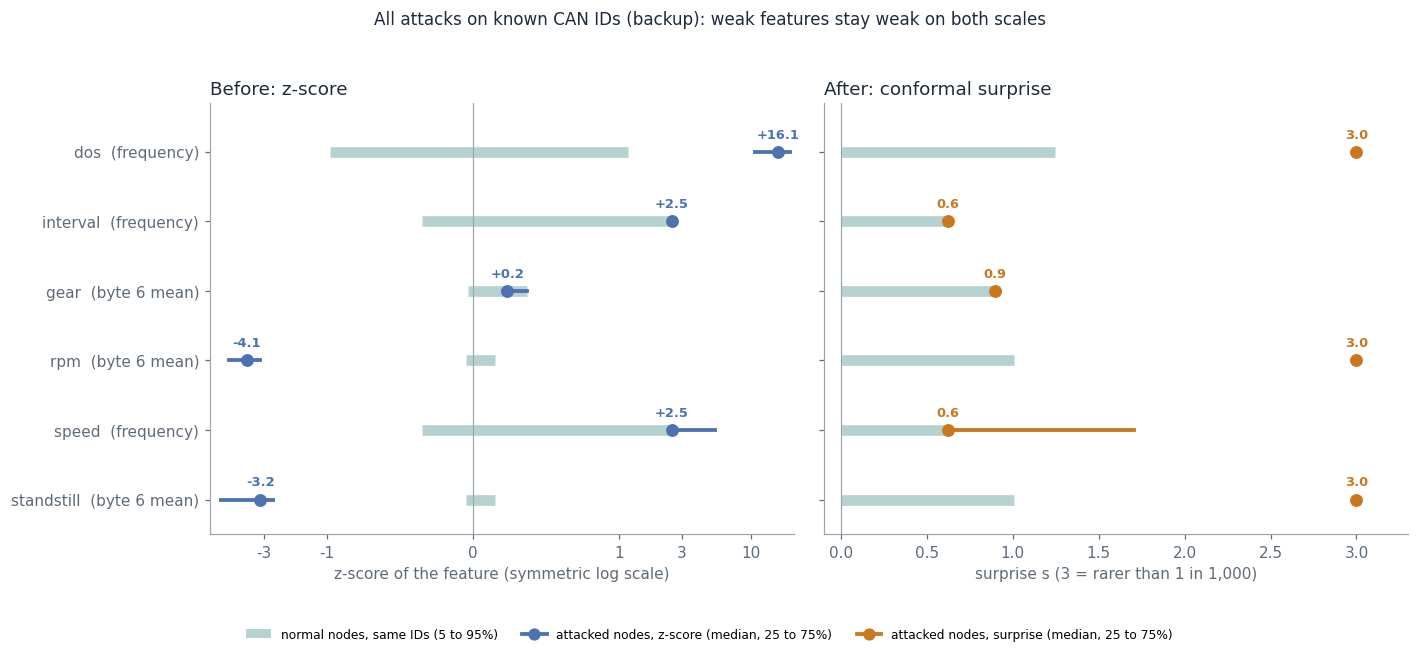

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def auroc(pos, neg):
    if len(pos) < 5 or len(neg) < 5:
        return np.nan
    r = pd.Series(np.concatenate([pos, neg])).rank().values
    a = (r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))
    return max(a, 1 - a)

def class_nodes(T, c):
    ci = CLASS_NAMES.index(c)
    pos = (T["cls"] == ci) & T["atk"]
    ids = np.unique(T["cid"][pos])
    neg = (T["cls"] == 0) & np.isin(T["cid"], ids)
    return pos, neg, ids

rng = np.random.default_rng(0)
def sub(v, n=4000):
    return v if len(v) <= n else rng.choice(v, n, replace=False)

rows, picked = [], {}
for c in ATTACKS_ALL:
    pos_o, neg_o, ids = class_nodes(OLD, c)
    pos_n, neg_n, _ = class_nodes(NEW, c)
    if pos_o.sum() < 5:
        continue
    aucs = [auroc(sub(OLD["xb"][pos_o, k]), sub(OLD["xb"][neg_o, k])) for k in range(12)]
    k = int(np.nanargmax(aucs)); picked[c] = k
    zo = OLD["xb"][pos_o, k]; sn = NEW["xb"][pos_n, k]
    lo_o, hi_o = np.quantile(OLD["xb"][neg_o, k], [0.05, 0.95])
    rows.append({"attack": c, "target IDs": ", ".join(OLD["id_hex"](int(i)) for i in ids[:3]),
                 "feature": BASE_NAMES[k], "attacked nodes": int(pos_o.sum()),
                 "old: median z": np.median(zo),
                 "old: outside normal 5-95%": bool(np.median(zo) < lo_o or np.median(zo) > hi_o),
                 "old: AUROC": aucs[k], "new: median s": np.median(sn),
                 "new: AUROC": auroc(sub(sn), sub(NEW["xb"][neg_n, k]))})
att = pd.DataFrame(rows).set_index("attack")
display(att.round(3))

def draw_two_scales(classes, title, name):
    classes = [c for c in classes if c in att.index]
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.62 * len(classes) + 1.9), sharey=True)
    y = np.arange(len(classes))
    for ax, T, sub_title, col in ((axes[0], OLD, "Before: z-score", BLUE),
                                  (axes[1], NEW, "After: conformal surprise", OCHRE)):
        for i, c in enumerate(classes):
            pos, neg, _ = class_nodes(T, c); k = picked[c]
            lo, hi = np.quantile(T["xb"][neg, k], [0.05, 0.95])
            ax.plot([lo, hi], [i, i], color=TEAL, lw=7, alpha=0.35, solid_capstyle="butt")
            v = T["xb"][pos, k]
            q1, med, q3 = np.quantile(v, [0.25, 0.5, 0.75])
            ax.plot([q1, q3], [i, i], color=col, lw=2.5)
            ax.scatter([med], [i], color=col, s=55, zorder=3)
            ax.annotate(f"{med:+.1f}" if T is OLD else f"{med:.1f}", (med, i), textcoords="offset points",
                        xytext=(0, 9), ha="center", fontsize=8.5, color=col, fontweight="bold")
        ax.axvline(0, color=LINE, lw=0.8)
        ax.set_title(sub_title, loc="left", fontsize=12, color=INK)
    axes[0].set_xscale("symlog", linthresh=1); axes[0].set_xlabel("z-score of the feature (symmetric log scale)")
    ticks = [t for t in (-100, -30, -10, -3, -1, 0, 1, 3, 10, 30, 100)
             if axes[0].get_xlim()[0] <= t <= axes[0].get_xlim()[1]]
    axes[0].set_xticks(ticks); axes[0].set_xticklabels([str(t) for t in ticks])
    axes[1].set_xlim(-0.1, 3.3); axes[1].set_xlabel("surprise s (3 = rarer than 1 in 1,000)")
    axes[0].set_yticks(y); axes[0].set_yticklabels([f"{c}  ({att.loc[c, 'feature']})" for c in classes])
    axes[0].set_ylim(len(classes) - 0.5, -0.7)

    # legend: one entry per meaning, with the colour used in each panel
    handles = [
        Patch(facecolor=TEAL, alpha=0.35, label="normal nodes, same IDs (5 to 95%)"),
        Line2D([0], [0], color=BLUE, lw=2.5, marker="o", markersize=7,
               label="attacked nodes, z-score (median, 25 to 75%)"),
        Line2D([0], [0], color=OCHRE, lw=2.5, marker="o", markersize=7,
               label="attacked nodes, surprise (median, 25 to 75%)"),
    ]
    fig.suptitle(title, y=1.03, fontsize=11, color=INK)
    fig.tight_layout(rect=[0, 0.08, 1, 1])
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, frameon=False)
    savefig(name); plt.show()

draw_two_scales(ATTACKS_SLIDE, "Strong deviations: different z-scores (size and sign), the same surprise value",
                "fig2_attacks_two_scales")
draw_two_scales(ATTACKS_ALL, "All attacks on known CAN IDs (backup): weak features stay weak on both scales",
                "fig2b_attacks_two_scales_all")

## 4. Payload continuity

**4a.** Một chuỗi frame thật của một CAN ID quanh frame bị chèn đầu tiên trong file attack (mặc định: file `rpm`, ID 0x0C9). Byte được vẽ là byte thay đổi nhiều nhất trong đoạn đó.

**4b.** Phân bố đặc trưng `payload spike` (mức bất ngờ) của node bị tấn công so với node bình thường cùng ID, cho từng attack giả mạo.

[rpm] CAN ID 0x0C9: 10776 injected frames, counter-like bytes [3], largest jump 250
[gear] CAN ID 0x1F5: 9483 injected frames, counter-like bytes [], largest jump 55
[speed] CAN ID 0x3E9: 14147 injected frames, counter-like bytes [], largest jump 253
[standstill] CAN ID 0x0C9: 5259 injected frames, counter-like bytes [3], largest jump 255


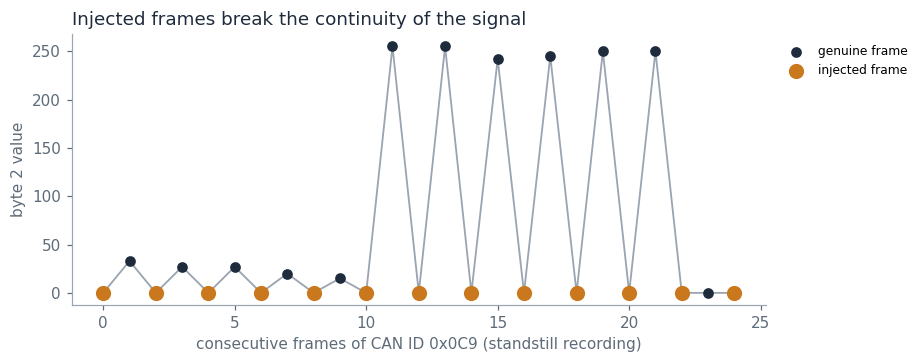

Shown: standstill, CAN ID 0x0C9, byte 2, jump 255


In [11]:
RAW_ATTACKS = ["rpm", "gear", "speed", "standstill"]   # files to search; the clearest case is drawn
CONTEXT = 12                # genuine frames shown on each side of the chosen injected frame

def find_csv(stem):
    for d in (RAW_DIR, RAW_DIR.parent):                    # merged/ or the vehicle folder itself
        for p in sorted(d.glob("*.csv")):
            if p.stem.lower() == stem:
                return p
    return None

def to_id(series):
    # integers are decimal CAN IDs (can-ml); strings are hex ("0C9" or "0x0C9")
    if pd.api.types.is_numeric_dtype(series):
        return series.astype("int64")
    return series.astype(str).str.strip().str.lower().str.replace("0x", "", regex=False).apply(
        lambda v: int(v, 16) if v else -1)

def attack_flag(series):
    if pd.api.types.is_numeric_dtype(series):
        return series.fillna(0).values > 0
    return series.astype(str).str.strip().str.lower().isin(["1", "1.0", "true", "t", "yes", "attack"]).values

def payload_matrix(series):
    s = series.astype(str).str.replace(" ", "", regex=False).str.ljust(16, "0").str[:16]
    return np.array([[int(v[i:i + 2], 16) for i in range(0, 16, 2)] for v in s], dtype=float)

def scan(stem):
    """Frames of the most attacked CAN ID in one attack file, and its clearest injected frame."""
    path = find_csv(stem)
    if path is None:
        print(f"[{stem}] file not found"); return None
    cols = {c.lower().strip(): c for c in pd.read_csv(path, nrows=1).columns}
    id_c = next(cols[k] for k in ("arbitration_id", "can_id", "id") if k in cols)
    atk_c = next(cols[k] for k in ("attack", "label", "flag") if k in cols)
    dat_c = next(cols[k] for k in ("data_field", "data", "payload") if k in cols)

    counts = {}                                            # pass 1: most attacked CAN ID
    for ch in pd.read_csv(path, usecols=[id_c, atk_c], chunksize=500_000):
        ids, atk = to_id(ch[id_c]).values, attack_flag(ch[atk_c])
        for i, n in zip(*np.unique(ids[atk], return_counts=True)):
            counts[int(i)] = counts.get(int(i), 0) + int(n)
    if not counts:
        print(f"[{stem}] no injected frame"); return None
    target = max(counts, key=counts.get)

    parts = []                                             # pass 2: every frame of that ID, in time order
    for ch in pd.read_csv(path, usecols=[id_c, atk_c, dat_c], chunksize=500_000):
        parts.append(ch[to_id(ch[id_c]).values == target])
    fr = pd.concat(parts, ignore_index=True)
    B, is_atk = payload_matrix(fr[dat_c]), attack_flag(fr[atk_c])

    # counter-like bytes change on almost every genuine frame: never shown
    gen = B[~is_atk]
    change_rate = (np.diff(gen, axis=0) != 0).mean(0) if len(gen) > 1 else np.zeros(8)
    counter = change_rate > 0.9

    # for every injected frame: distance to the genuine frames just before and after it
    g_idx = np.where(~is_atk)[0]
    best = (0.0, None, None)
    for i in np.where(is_atk)[0]:
        k = np.searchsorted(g_idx, i)
        if k == 0 or k == len(g_idx):
            continue
        prev, nxt = B[g_idx[k - 1]], B[g_idx[k]]
        d = np.minimum(np.abs(B[i] - prev), np.abs(B[i] - nxt))   # departs from both neighbours
        d[counter] = 0
        if d.max() > best[0]:
            best = (float(d.max()), int(i), int(np.argmax(d)))
    print(f"[{stem}] CAN ID 0x{target:03X}: {int(is_atk.sum())} injected frames, "
          f"counter-like bytes {np.where(counter)[0].tolist()}, largest jump {best[0]:.0f}")
    return {"stem": stem, "target": target, "B": B, "is_atk": is_atk,
            "jump": best[0], "pos": best[1], "byte": best[2]}

found = [r for r in (scan(s) for s in RAW_ATTACKS) if r is not None]
found = [r for r in found if r["pos"] is not None and r["jump"] > 0]
if not found:
    print("No injected frame departs from its neighbours on a non-counter byte: leave this figure out.")
else:
    r = max(found, key=lambda r: r["jump"])                 # clearest case across the files
    lo, hi = max(0, r["pos"] - CONTEXT), r["pos"] + CONTEXT + 1
    vals, atk = r["B"][lo:hi, r["byte"]], r["is_atk"][lo:hi]
    t = np.arange(len(vals))
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    ax.plot(t, vals, color=LINE, lw=1.2, zorder=1)
    ax.scatter(t[~atk], vals[~atk], s=36, color=INK, zorder=2, label="genuine frame")
    ax.scatter(t[atk], vals[atk], s=80, color=OCHRE, zorder=3, label="injected frame")
    ax.set_xlabel(f"consecutive frames of CAN ID 0x{r['target']:03X} ({r['stem']} recording)")
    ax.set_ylabel(f"byte {r['byte']} value")
    ax.set_title("Injected frames break the continuity of the signal", loc="left", fontsize=12, color=INK)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    fig.tight_layout(); savefig("fig3a_payload_sequence"); plt.show()
    print(f"Shown: {r['stem']}, CAN ID 0x{r['target']:03X}, byte {r['byte']}, jump {r['jump']:.0f}")

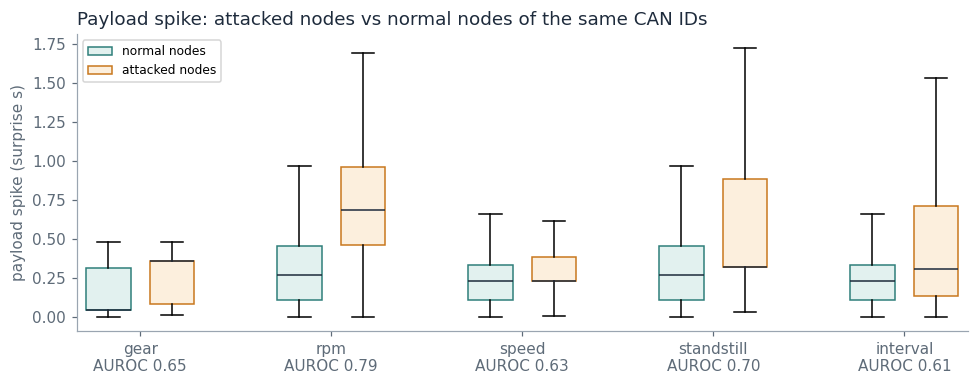

In [6]:
if NEW["n_feat"] >= 15:
    k_spike = 13                                    # base 12 + jump, spike, changed
    spoof = [c for c in ("gear", "rpm", "speed", "standstill", "interval") if c in CLASS_NAMES]
    data, labels, aucs = [], [], []
    for c in spoof:
        pos, neg, _ = class_nodes(NEW, c)
        if pos.sum() < 5:
            continue
        data += [NEW["xb"][neg, k_spike], NEW["xb"][pos, k_spike]]
        labels.append(c); aucs.append(auroc(sub(NEW["xb"][pos, k_spike]), sub(NEW["xb"][neg, k_spike])))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    pos_x = np.concatenate([[3 * i, 3 * i + 1] for i in range(len(labels))])
    bp = ax.boxplot(data, positions=pos_x, widths=0.7, showfliers=False, patch_artist=True,
                    medianprops={"color": INK})
    for j, b in enumerate(bp["boxes"]):
        b.set_facecolor(TEAL_L if j % 2 == 0 else OCHRE_L); b.set_edgecolor(TEAL if j % 2 == 0 else OCHRE)
    ax.set_xticks([3 * i + 0.5 for i in range(len(labels))])
    ax.set_xticklabels([f"{c}\nAUROC {a:.2f}" for c, a in zip(labels, aucs)])
    ax.set_ylabel("payload spike (surprise s)")
    ax.set_title("Payload spike: attacked nodes vs normal nodes of the same CAN IDs", loc="left", fontsize=12, color=INK)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor=TEAL_L, edgecolor=TEAL, label="normal nodes"),
                       Patch(facecolor=OCHRE_L, edgecolor=OCHRE, label="attacked nodes")], fontsize=8)
    fig.tight_layout(); savefig("fig3b_payload_spike"); plt.show()
else:
    print("The new data set has no payload features (run preprocessing with --payload_features).")

## 5. Bảng tổng hợp

In [ ]:
att.to_csv(FIG / "attacks_two_scales.csv"); summary.to_csv(FIG / "normal_scale_p99.csv")
print("Saved to", FIG.resolve())
display(att[["feature", "old: median z", "old: outside normal 5-95%", "new: median s", "old: AUROC", "new: AUROC"]].round(3))
slide = att.loc[[c for c in ATTACKS_SLIDE if c in att.index]]
print("For the slide bullet: " + "; ".join(f"{c}: z = {r['old: median z']:+.1f} -> s = {r['new: median s']:.1f}"
                                           for c, r in slide.iterrows()))